# Context-Dependent Decision Making Task

This environment implements a context-dependent perceptual decision-making task, in which the agent has to perform a perceptual decision that depends on a context that is explicitly indicated on each trial. The environment is a simplified version of the original task ([Mante et al. 2013](https://www.nature.com/articles/nature12742)), that tests the agents' ability to flexibly switch between different contexts by making them choose between two options (left or right) based on the stimulus evidence associated with the relevant context (e.g., motion and color). The key features of the task are:

1. The relevant context is explicitly signaled on each trial.
2. Choices are represented as angles evenly spaced around a circle. Note that the number of choices can be configured via `dim_ring`. With the default of 2 choices, this corresponds to:

   - Position 1: 0° (left choice)
   - Position 2: 180° (right choice)

3. Stimulus for each context is represented as a cosine modulation peaked at one of these positions.
4. The correct choice (ground truth) is randomly chosen on each trials (for 2 choices: left or right).
5. The stimulus evidence (coherence) of each context is also randomly chosen on each trial.

For example, if the context signal indicates modality 0, the agent must:

- Choose position 1 (left) when context 0's coherence peaks at 0°
- Choose position 2 (right) when context 0's coherence peaks at 180°

In this notebook, we will:

1. Train an agent on the task using supervised learning and reinforcement learning with [Stable-Baselines3](https://stable-baselines3.readthedocs.io/).
2. Compare the behavior of agents trained with supervised learning and reinforcement learning.


# 0. Install Dependencies

To begin, install the `neurogym` package. This will automatically install all required dependencies, including Stable-Baselines3.

For detailed instructions on how to install `neurogym` within a conda environment or in editable mode, refer to the [installation instructions](https://github.com/neurogym/neurogym?tab=readme-ov-file#installation).


In [1]:
# Uncomment to install
# ! pip install neurogym[rl]

# 1. Training an Agent on the Context-Dependent Decision Making Task


## 1.1 Environment Setup and Initial Agent Behavior

Let's now create and explore the environment using the `ContextDecisionMaking` class from neurogym. We'll use the default configuration for explicit context mode (`use_expl_context = True`) which includes:

- `dim_ring = 2`: Two possible choices (left/right) represented at 0° and 180°. Note that the ring architecture can support any number of choices, making it suitable for more complex decision-making scenarios. The environment will provide context signals indicating which modality is relevant for each trial, allowing the agent to flexibly adapt its decision strategy.
- `timing = {'fixation': 300, 'stimulus': 750, 'delay': ~600, 'decision': 100}` (in milliseconds).
- `rewards = {'abort': -0.1, 'correct': +1.0}`; abort is a penalty applied when the agent fails to fixate. The task allows the trial to be aborted if fixation does not occur, which is where the name of this penalty comes from.
- `sigma = 1.0`: Standard deviation of the noise added to the inputs.


### 1.1.1 Import Libraries


In [2]:
import warnings
from IPython.display import clear_output
import matplotlib.pyplot as plt
import numpy as np
import neurogym as ngym
import torch.nn as nn
import torch
import os
from stable_baselines3.common.env_checker import check_env
from sb3_contrib import RecurrentPPO
from stable_baselines3.common.vec_env import DummyVecEnv
from neurogym.wrappers import Monitor
from neurogym.utils import TruncExp, plot_psychometric, plot_env

# Suppress warnings
warnings.filterwarnings("ignore")
clear_output()

### 1.1.2 Environment Setup


In [3]:
# Environment parameters
# These settings are low to speed up testing; we recommend setting EVAL_TRIALS to at least 1000 and TRAIN_TRIALS to at least 6000
EVAL_TRIALS = 1000
TRAIN_TRIALS = 6000  # Choose the desired number of trials
use_expl_context = True  # Use explicit context mode

# These are the default values, shown here to demonstrate how they can be modified:
dt = 100
dim_ring = 2  # Number of choices in the ring representation
abort = False  # Whether to allow aborting the trial if the agent does not fixate
rewards = {
    "abort": -0.1,
    "correct": +1.0,
    "fail": 0.0
}
timing = {
    "fixation": 300,
    "stimulus": 750,
    "delay": TruncExp(600, 300, 3000),
    "decision": 100,
}
sigma = 1.0 # Standard deviation of the Gaussian noise in the ring representation

# We can modify any of these parameters by passing them to ngym.make():
kwargs = {
    "use_expl_context": use_expl_context,
    "dt": dt,
    "dim_ring": dim_ring,
    "rewards": rewards,
    "timing": timing,
    "sigma": sigma,
    "abort": abort,
}

# Create and wrap the environment
task = "ContextDecisionMaking-v0"
env = ngym.make(task, **kwargs)

# Check the custom environment and output additional warnings (if any)
check_env(env)

# Print environment specifications
print("Trial timing (in milliseconds):")
print(env.timing)

print("\nObservation space structure:")
print(env.observation_space)
print("Observation components:")
print(env.observation_space.name)

print("\nAction space structure:")
print(env.action_space)
print("Action mapping:")
print(env.action_space.name)

Trial timing (in milliseconds):
{'fixation': 300, 'stimulus': 750, 'delay': <neurogym.utils.ngym_random.TruncExp object at 0x7f6df3b87a50>, 'decision': 100}

Observation space structure:
Box(-inf, inf, (7,), float32)
Observation components:
{'fixation': 0, 'stim1_mod1': 1, 'stim2_mod1': 2, 'stim1_mod2': 3, 'stim2_mod2': 4, 'context1': 5, 'context2': 6}

Action space structure:
Discrete(3)
Action mapping:
{'fixation': 0, 'choice': [1, 2]}


### 1.1.3 Random Agent Behavior

Let's now plot the behavior of a random agent on the task. The agent will randomly choose between the two options (left/right, blue line), and we will visualize its behavior over 5 trials. We will also plot the reward received by the agent at each time step, as well as the performance on each trial. Note that performance is only defined at the end of a trial: it is 1 if the agent made the correct choice, and 0 otherwise.

To keep track of the agent's behavior, we will use the `Monitor` wrapper, which monitors training by:

- Tracking and saving behavioral data (rewards, actions, observations) every `sv_per` steps.
- Generating visualization figures during training if` sv_fig=True`.
- Providing progress information if `verbose=True`.

Here, we’ll use the wrapper solely to compute the agent’s performance, but later it will help us assess learning and save intermediate results.



Evaluating random policy performance...


Neurogym | 2025-07-19@20:37:08 | Completed 1000/1000 trials



Random policy metrics (1,000 trials):
Mean performance: 0.3350
Mean reward: 0.3350


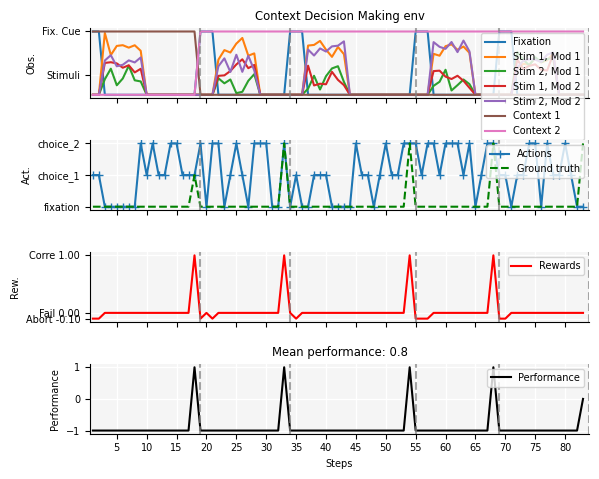

In [4]:
obs, info = env.reset()

# Visualize example trials
fig = plot_env(
    env,
    name='Context Decision Making',
    ob_traces=[
        'Fixation',
        'Stim 1, Mod 1',  # First stimulus component of modality 1
        'Stim 2, Mod 1',  # Second stimulus component of modality 1
        'Stim 1, Mod 2',  # First stimulus component of modality 2
        'Stim 2, Mod 2',  # Second stimulus component of modality 2
        'Context 1',      # First context signal
        'Context 2',      # Second context signal
    ],
    num_trials=5
)

# Evaluate performance of the environment before training
eval_monitor = Monitor(
    env
)
print("\nEvaluating random policy performance...")
metrics = eval_monitor.evaluate_policy(num_trials=EVAL_TRIALS)
print(f"\nRandom policy metrics ({EVAL_TRIALS:,} trials):")
print(f"Mean performance: {metrics['mean_performance']:.4f}")
print(f"Mean reward: {metrics['mean_reward']:.4f}")

As we can see, the agent's behavior is entirely random. It does not learn to fixate or to choose the correct option based on contextual cues. As a result, its performance is also random. Through training, we expect the agent to improve by learning to respect the fixation period, use context cues to infer the relevant context, and map signal peaks to the correct choices in the ring representation. Let’s move on to training the agent to see whether it can learn these key aspects of the task.


## 1.2 Training and Evaluating the Agent

We will now train the agent using Stable-Baselines3’s implementation of [PPO (Proximal Policy Optimization)](https://stable-baselines3.readthedocs.io/en/master/modules/ppo.html), a widely used reinforcement learning algorithm known for its stability and efficiency.

To support recurrent policies, we will use [RecurrentPPO](https://sb3-contrib.readthedocs.io/en/master/modules/ppo_recurrent.html#recurrent-ppo), which extends PPO with recurrent neural networks, specifically LSTMs.


### 1.2.1 Training the Agent


In [6]:
# Set the number of trials to train on
trial_length_stats = env.trial_length_stats(num_trials=EVAL_TRIALS)
avg_timesteps = int(trial_length_stats["mean"])
total_timesteps = TRAIN_TRIALS * avg_timesteps
print(f"Training for {TRAIN_TRIALS:,} trials ≈ {total_timesteps:,} timesteps")

# Configure monitoring with trial-appropriate parameters
trials_per_figure = 10  # Show 10 trials in each figure
steps_per_figure = int(trials_per_figure * avg_timesteps)

train_monitor = Monitor(
    env,
    trigger="trial",              # Save based on completed trials
    interval=1000,                # Save data every 1000 trials
    plot_create=True,             # Save visualization figures
    plot_steps=steps_per_figure,  # Number of steps to visualize on the figure
    verbose=True,                 # Print stats when data is saved
)

# DummyVecEnv is Stable-Baselines3 wrapper that converts the environment
# into a vectorized form (required by PPO), allowing for parallel training of multiple environments
env_vec = DummyVecEnv([lambda: train_monitor])

# Create and train Recurrent PPO agent
# Set n_steps to be a multiple of your average trial length
trials_per_batch = 64
n_steps = int(avg_timesteps * trials_per_batch)  # Collect approximately 64 trials per update
batch_size = 32  # Small batch size for short episodes
policy_kwargs = {
    "lstm_hidden_size": 128,
    "n_lstm_layers": 1,
    "shared_lstm": True,          # Share LSTM to reduce parameters
    "enable_critic_lstm": False,  # Disable separate LSTM for critic when sharing
    "EISep": False
}
rl_model = RecurrentPPO(
    "MlpLstmPolicy",
    env_vec,
    learning_rate=3e-4,
    n_steps=n_steps,          # Align with multiple complete episodes
    batch_size=32,            # Smaller batch size
    ent_coef=0,               # Entropy coefficient
    policy_kwargs=policy_kwargs,
    verbose=1
)

rl_model.learn(total_timesteps=total_timesteps, log_interval=int(total_timesteps/10))
env_vec.close()

Training for 6,000 trials ≈ 114,000 timesteps
Using cuda device


Neurogym | 2025-07-19@20:40:46 | --------------------
Neurogym | 2025-07-19@20:40:46 | Data saved to: /home/geert/neurogym/docs/examples/runs/ContextDecisionMaking/2025-07-19_12-39-02/trial_1000.npz
Neurogym | 2025-07-19@20:40:46 | Number of trials: 1000
Neurogym | 2025-07-19@20:40:46 | Average reward: 0.446
Neurogym | 2025-07-19@20:40:46 | Average performance: 0.446
Neurogym | 2025-07-19@20:40:46 | --------------------
Neurogym | 2025-07-19@20:42:22 | --------------------
Neurogym | 2025-07-19@20:42:22 | Data saved to: /home/geert/neurogym/docs/examples/runs/ContextDecisionMaking/2025-07-19_12-39-02/trial_2000.npz
Neurogym | 2025-07-19@20:42:22 | Number of trials: 2000
Neurogym | 2025-07-19@20:42:22 | Average reward: 0.556
Neurogym | 2025-07-19@20:42:22 | Average performance: 0.556
Neurogym | 2025-07-19@20:42:22 | --------------------
Neurogym | 2025-07-19@20:43:44 | --------------------
Neurogym | 2025-07-19@20:43:44 | Data saved to: /home/geert/neurogym/docs/examples/runs/ContextDec

### 1.2.2 Plot the Behavior of the Trained Agent


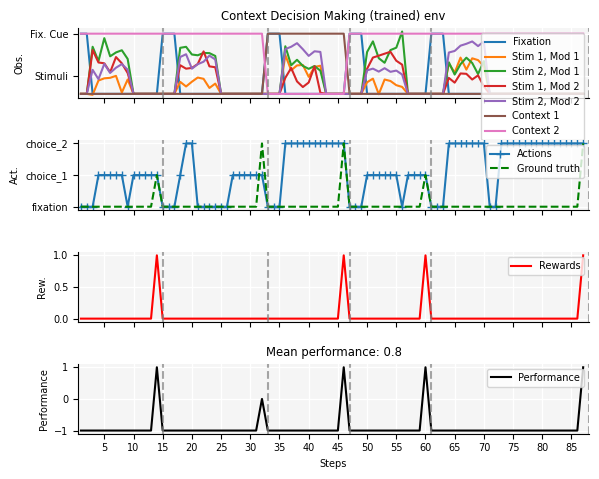

In [7]:
# Plot example trials with trained agent
fig = plot_env(
    env_vec,
    name='Context Decision Making (trained)',
    ob_traces=[
        'Fixation',
        'Stim 1, Mod 1',  # First stimulus component of modality 1
        'Stim 2, Mod 1',  # Second stimulus component of modality 1
        'Stim 1, Mod 2',  # First stimulus component of modality 2
        'Stim 2, Mod 2',  # Second stimulus component of modality 2
        'Context 1',      # First context signal
        'Context 2',      # Second context signal
    ],
    num_trials=5,
    model=rl_model,
)

After training, we visualize the agent's behavior on a few example trials. In contrast to the random agent, we should now see:

- Consistent fixation maintenance during the fixation period
- Choices that correlate with the evidence in the modality indicated by the context signal
- No systematic relationship between choices and signals from the irrelevant modality
- Performance significantly above chance level (0.5), reflecting successful context-dependent decisions

The plot shows the trained agent's behavior across 5 example trials, allowing us to visualize how well it has learned to flexibly switch its attention between modalities based on the context signal and make appropriate choices using the ring representation.


### 1.2.3 Evaluate the Agent's Performance



Evaluating trained model performance...


Neurogym | 2025-07-19@18:16:37 | Completed 1000/1000 trials
Neurogym | 2025-07-19@18:16:37 | Found 5 data files
Neurogym | 2025-07-19@18:16:37 | Figure saved to /home/geert/neurogym/docs/examples/runs/ContextDecisionMaking_training_history.png



Trained model metrics (1,000 trials):
Mean performance: 0.5240
Mean reward: 0.5240


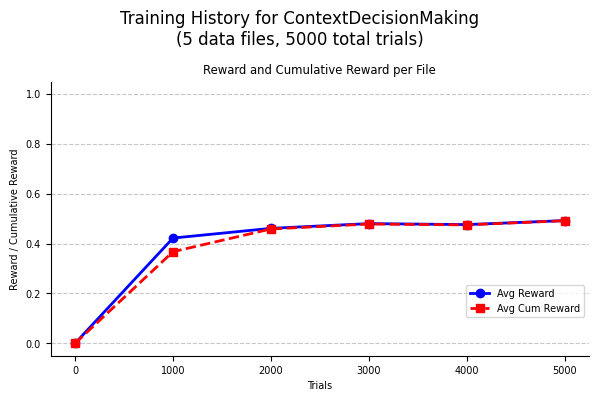

In [ ]:
# Evaluate performance of the trained model
print("\nEvaluating trained model performance...")
rl_trained_metrics = eval_monitor.evaluate_policy(num_trials=EVAL_TRIALS, model=rl_model)
print(f"\nTrained model metrics ({EVAL_TRIALS:,} trials):")
print(f"Mean performance: {rl_trained_metrics['mean_performance']:.4f}")
print(f"Mean reward: {rl_trained_metrics['mean_reward']:.4f}")

fig = train_monitor.plot_training_history(figsize=(6, 4), plot_performance=False)

### 1.2.4 Plot the Agent's Psychometric Curves


Neurogym | 2025-07-19@18:02:16 | Completed 1000/1000 trials


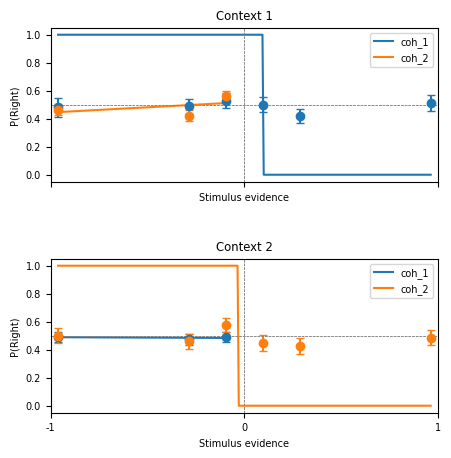

In [ ]:
if not os.getenv("GITHUB_ACTIONS"):
    # Evaluate policy and extract data
    eval_monitor.evaluate_policy(num_trials=EVAL_TRIALS, model=rl_model)
    data = eval_monitor.data_eval

    # Extract trial-level fields
    trials = data['trial']
    other_choices = np.array([trial['other_choice'] == 2 for trial in trials], dtype=int)
    coh_1 = np.array([trial['coh_1'] for trial in trials])
    coh_2 = np.array([trial['coh_2'] for trial in trials])
    contexts = np.array([trial['context'] for trial in trials])

    # Filter out trials where action is 0 (no action taken)
    actions_only_mask = data['action'] != 0
    data_action = data['action'][actions_only_mask]
    data_gt = data['gt'][actions_only_mask]
    data_oc = other_choices[actions_only_mask]
    coh_1 = coh_1[actions_only_mask]
    coh_2 = coh_2[actions_only_mask]
    contexts = contexts[actions_only_mask]

    # Convert actions and ground truth to binary (0 = left, 1 = right)
    choices = (data_action == 2).astype(int)
    ground_truth = (data_gt == 2).astype(int)
    data_oc = (data_oc == 2).astype(int)

    # Plotting setup
    fig, axs = plt.subplots(2, 1, figsize=(5, 5), sharex=True, sharey=True,
                            gridspec_kw={'hspace': 0.5})

    evidence_sources = [('coh_1', coh_1), ('coh_2', coh_2)]
    context_ids = [0, 1]

    # Plot psychometric curves for each context and evidence type
    for i, context_id in enumerate(context_ids):
        ax = axs[i]
        title = f'Context {context_id + 1}'

        for j, (label, evidence) in enumerate(evidence_sources):
            # Filter trials matching current context
            mask = contexts == context_id
            ev = evidence[mask]
            ch = choices[mask]

            # Choose correct reference: ground truth or other agent
            reference = ground_truth[mask] if context_id == j else data_oc[mask]

            # Signed evidence: negative if correct answer is left
            signed_ev = np.where(reference == 0, -ev, ev)

            plot_psychometric(signed_ev, ch, ax, title=title, legend=label)

    plt.tight_layout()
    plt.show()

# 2. Learning the Task as a Supervised Problem

We will now train the agent using supervised learning. NeuroGym provides functionality to generate a dataset directly from the environment, allowing us to sample batches of inputs and corresponding labels for training.


## 2.1 Converting the Environment to a Supervised Dataset


### 2.1.1 Dataset Setup


In [ ]:
# Environment parameters
task = 'ContextDecisionMaking-v0'
kwargs = {
    "use_expl_context": use_expl_context,
    "dt": dt,
    "dim_ring": dim_ring,
    "rewards": rewards,
    "timing": timing,
    "sigma": sigma,
    "abort": abort,
}

# Set seq_len to capture 95% of trials, and multiply by 2
seq_len = 2*int(trial_length_stats["percentile_95"])
print(f"Using sequence length: {seq_len}")

# Make supervised dataset
print(f"Creating dataset with batch_size={batch_size}")
dataset = ngym.Dataset(task, env_kwargs=kwargs, batch_size=batch_size, seq_len=seq_len)

env = dataset.env

# Extract dimensions from environment
ob_size = env.observation_space.shape[0]
act_size = env.action_space.n

print(f"Observation size: {ob_size}")
print(f"Action size: {act_size}")

# Get a batch of data
inputs, target = dataset()

# Display shapes and content
print(f"Input batch shape: {inputs.shape}")
print(f"Target batch shape: {target.shape}")

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using sequence length: 60
Creating dataset with batch_size=32
Observation size: 7
Action size: 3
Input batch shape: (60, 32, 7)
Target batch shape: (60, 32)
Using device: cuda


### 2.1.2 Model Setup


In [ ]:
class Net(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(Net, self).__init__()
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=False)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x, hidden=None):
        # Forward pass with hidden state tracking
        lstm_out, hidden = self.lstm(x, hidden)
        output = self.fc(lstm_out)
        return output, hidden

    def init_hidden(self, batch_size, device):
        """Initialize hidden state"""
        h0 = torch.zeros(1, batch_size, self.hidden_size).to(device)
        c0 = torch.zeros(1, batch_size, self.hidden_size).to(device)
        return (h0, c0)

# Create the model
hidden_size = 128
sl_model = Net(
    input_size=ob_size,
    hidden_size=hidden_size,
    output_size=act_size,
).to(device)

## 2.2 Training and Evaluating a Neural Network Model


### 2.2.1 Training the Model


inputs shape: (60, 32, 7)
targets shape: (60, 32)
Epoch [0/10], Loss: 1.1027
inputs shape: (60, 32, 7)
targets shape: (60, 32)
inputs shape: (60, 32, 7)
targets shape: (60, 32)
inputs shape: (60, 32, 7)
targets shape: (60, 32)
inputs shape: (60, 32, 7)
targets shape: (60, 32)
inputs shape: (60, 32, 7)
targets shape: (60, 32)
inputs shape: (60, 32, 7)
targets shape: (60, 32)
inputs shape: (60, 32, 7)
targets shape: (60, 32)
inputs shape: (60, 32, 7)
targets shape: (60, 32)
inputs shape: (60, 32, 7)
targets shape: (60, 32)
Finished Training


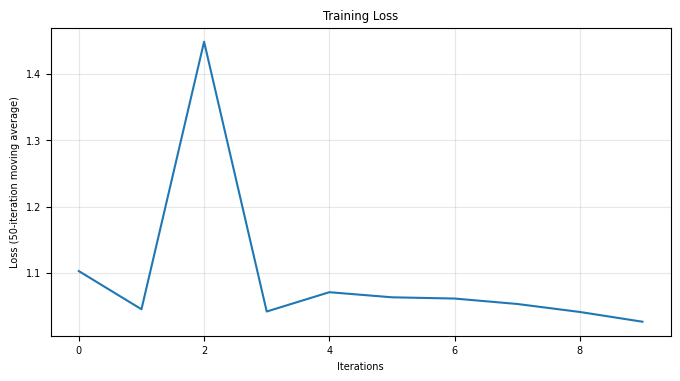

In [ ]:
# This setting is low to speed up testing, we recommend setting it to at least 1000
EPOCHS = 10

# This weighting deprioritizes class 0 while keeping classes 1 and 2 equally important,
# aligning with the reward distribution idea from the RL setting
class_weights = torch.tensor([0.05, 1, 1]).to(device)
# Define the optimizer and loss function
optimizer = torch.optim.Adam(sl_model.parameters(), lr=0.01, weight_decay=1e-5)
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Training loop
loss_history = []

for i in range(EPOCHS):
    # Get a batch of data
    inputs, targets = dataset()
    print('inputs shape:', inputs.shape)
    print('targets shape:', targets.shape)

    # Convert to PyTorch tensors
    inputs = torch.from_numpy(inputs).float().to(device)
    targets = torch.from_numpy(targets).long().to(device)

    # Initialize hidden state
    hidden = sl_model.init_hidden(inputs.size(1), device)

    # Zero gradients
    optimizer.zero_grad()

    # Forward pass with hidden state tracking
    outputs, _ = sl_model(inputs, hidden)

    # Reshape for CrossEntropyLoss
    outputs_flat = outputs.reshape(-1, outputs.size(2))
    targets_flat = targets.reshape(-1)

    # Calculate loss
    # Weight the loss to account for class imbalance (very low weight to 0s, higher weights to 1s and 2s)
    loss = criterion(outputs_flat, targets_flat)

    # Backward pass and optimize
    loss.backward()
    optimizer.step()

    # print statistics
    loss_history.append(loss.item())
    if i % 50 == 0:
        print('Epoch [{}/{}], Loss: {:.4f}'.format(i, EPOCHS, loss.item()))

print('Finished Training')

# Plot the loss curve
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title('Training Loss')
plt.xlabel('Iterations')
plt.ylabel('Loss (50-iteration moving average)')
plt.grid(True, alpha=0.3)
plt.show()

### 2.2.2 Evaluate the Model's Performance


In [ ]:
verbose = False
# Evaluate performance of the trained model
sl_model.eval()

data_sl = {"action": [], "gt": [], "oc": [], "trial": []}
total_correct = 0
total_trials = 0

# Evaluate for specified number of trials
print(f"Evaluating model performance across {EVAL_TRIALS} trials...")

for i in range(EVAL_TRIALS):
    # Generate a new trial
    trial = env.new_trial()
    data_sl["trial"].append(trial)
    ob, gt = env.ob, env.gt
    data_sl["gt"].append(gt[-1])
    data_sl["oc"].append(trial['other_choice'])
    if verbose:
        print("observation shape:", ob.shape)
        print("ground truth shape:", gt.shape)

    # Handle potentially variable-length trials
    trial_length = ob.shape[0]

    # Add batch dimension to observation
    ob = ob[:, np.newaxis, :]

    # Convert to tensor
    inputs = torch.from_numpy(ob).float().to(device)
    if verbose:
        print("inputs shape:", inputs.shape)

    # Initialize hidden state for new trial
    hidden = sl_model.init_hidden(1, device)

    with torch.no_grad():
        outputs, _ = sl_model(inputs, hidden)
        pred_actions = torch.argmax(outputs, dim=2)
        data_sl["action"].append(pred_actions[-1, 0].cpu().numpy())
        if verbose:
            print("outputs shape:", outputs.shape)
            print("predicted actions shape:", pred_actions.shape)
            print("predicted actions:", pred_actions)
            print("ground truth:", gt)

    # Check only the decision period
    decision_idx = trial_length - 1  # Assuming decision is at the end
    is_correct = (gt[decision_idx] == pred_actions[decision_idx, 0].cpu().numpy())

    total_correct += is_correct

    if (i+1) % 100 == 0:
        print(f"Completed {i+1}/{EVAL_TRIALS} trials | Accuracy: {total_correct/(i+1):.4f}")

# Calculate mean performance
sl_mean_performance = total_correct / EVAL_TRIALS

for key in data_sl:
    if key != "trial":
        data_sl[key] = np.array(data_sl[key])

print(f"Mean performance across {EVAL_TRIALS} trials: {sl_mean_performance:.4f}")

Evaluating model performance across 1000 trials...
Completed 100/1000 trials | Accuracy: 0.0000
Completed 200/1000 trials | Accuracy: 0.0000
Completed 300/1000 trials | Accuracy: 0.0000
Completed 400/1000 trials | Accuracy: 0.0000
Completed 500/1000 trials | Accuracy: 0.0000
Completed 600/1000 trials | Accuracy: 0.0000
Completed 700/1000 trials | Accuracy: 0.0000
Completed 800/1000 trials | Accuracy: 0.0000
Completed 900/1000 trials | Accuracy: 0.0000
Completed 1000/1000 trials | Accuracy: 0.0000
Mean performance across 1000 trials: 0.0000


### 2.2.3 Plot the Model's Psychometric Curves


Neurogym | 2025-07-19@18:02:18 | Error while running 'plot_psychometric'.
Neurogym | 2025-07-19@18:02:18 | This may be due to a small sample size; please increase to get reasonable results.


ValueError: `ydata` must not be empty!

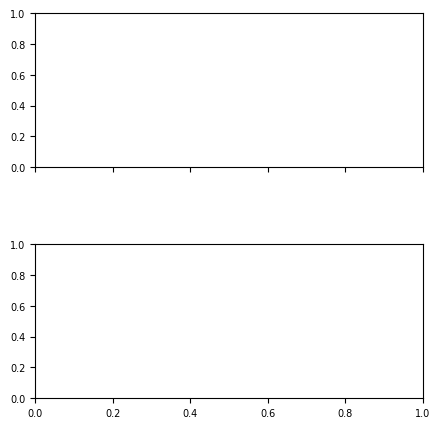

In [ ]:
if not os.getenv("GITHUB_ACTIONS"):
    # Extract trial-level fields
    trials = data_sl['trial']
    other_choices = np.array([trial['other_choice'] == 2 for trial in trials], dtype=int)
    coh_1 = np.array([trial['coh_1'] for trial in trials])
    coh_2 = np.array([trial['coh_2'] for trial in trials])
    contexts = np.array([trial['context'] for trial in trials])

    # Filter out trials where action is 0 (no action taken)
    actions_only_mask = data_sl['action'] != 0
    data_action = data_sl['action'][actions_only_mask]
    data_gt = data_sl['gt'][actions_only_mask]
    data_oc = other_choices[actions_only_mask]
    coh_1 = coh_1[actions_only_mask]
    coh_2 = coh_2[actions_only_mask]
    contexts = contexts[actions_only_mask]

    # Convert actions and ground truth to binary (0 = left, 1 = right)
    choices = (data_action == 2).astype(int)
    ground_truth = (data_gt == 2).astype(int)
    data_oc = (data_oc == 2).astype(int)

    # Plotting setup
    fig, axs = plt.subplots(2, 1, figsize=(5, 5), sharex=True, sharey=True,
                            gridspec_kw={'hspace': 0.5})

    evidence_sources = [('coh_1', coh_1), ('coh_2', coh_2)]
    context_ids = [0, 1]

    # Plot psychometric curves for each context and evidence type
    for i, context_id in enumerate(context_ids):
        ax = axs[i]
        title = f'Context {context_id + 1}'

        for j, (label, evidence) in enumerate(evidence_sources):
            # Filter trials matching current context
            mask = contexts == context_id
            ev = evidence[mask]
            ch = choices[mask]

            # Choose correct reference: ground truth or other agent
            reference = ground_truth[mask] if context_id == j else data_oc[mask]

            # Signed evidence: negative if correct answer is left
            signed_ev = np.where(reference == 0, -ev, ev)

            plot_psychometric(signed_ev, ch, ax, title=title, legend=label)

    plt.tight_layout()
    plt.show()

### 2.2.4 Comparing RL and SL Approaches


In [ ]:
# Print performance comparison
rl_performance = rl_trained_metrics['mean_performance']
sl_performance = sl_mean_performance

print(f"RL model performance: {rl_performance:.4f}")
print(f"SL model performance: {sl_performance:.4f}")